# Business problem statement

A leading financial institution wants to develop an intelligent Anti-Money Laundering detection system using Artificial Neural Networks to identify suspicious financial transactions. The existing rule-based system generates a large number of false alerts and fails to detect sophisticated money laundering patterns. The bank wants to leverage historical transaction data and customer behavioral patterns to build a predictive model that can classify transactions as legitimate or suspicious, thereby improving detection rates, reducing false positives, and supporting regulatory compliance

# Project Objective

The primary objective is to build a binary classification model using ANN to identify potentially suspicious financial transactions.

Technical objectives:
1. Analyze historical banking transaction data.
2. Perform exploratory data analysis (EDA).
3. Identify important transaction-level and customer-level features.
4. Handle missing values and categorical variables.
5. Apply feature scaling and preprocessing.
6. Handle imbalanced transaction classes.
7. Build an ANN architecture using TensorFlow/Keras.
8. Train the model to distinguish legitimate and suspicious transactions.
9. Optimize the model using hyperparameter tuning.
10. Evaluate the model using appropriate classification metrics.
11. Develop a prediction interface for real-time transaction monitoring.

# Expected business outcomes

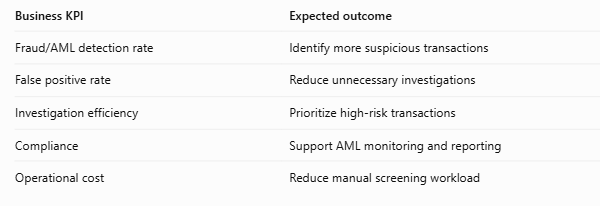

# Constraints

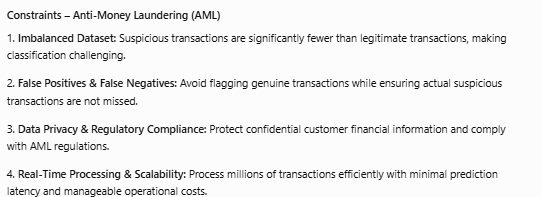

### 1 b) Data Understanding

#### Data Collection,Data Description

In [1]:
import kagglehub

In [2]:
link=r'berkanoztas/synthetic-transaction-monitoring-dataset-aml'
kagglehub.dataset_download(link,output_dir=r"C:\Users\Manchupally Ramesh\Downloads\amldataset")

'C:\\Users\\Manchupally Ramesh\\Downloads\\amldataset'

In [2]:
import pandas as pd
df=pd.read_csv(r"C:\Users\Manchupally Ramesh\Downloads\amldataset\SAML-D.csv")

In [3]:
df.shape

(9504852, 12)

In [4]:
df.head()

,Time,Date,Sender_account,Receiver_account,Amount,Payment_currency,Received_currency,Sender_bank_location,Receiver_bank_location,Payment_type,Is_laundering,Laundering_type
0,10:35:19,2022-10-07,8724731955,2769355426,1459.15,UK pounds,UK pounds,UK,UK,Cash Deposit,0,Normal_Cash_Deposits
1,10:35:20,2022-10-07,1491989064,8401255335,6019.64,UK pounds,Dirham,UK,UAE,Cross-border,0,Normal_Fan_Out
2,10:35:20,2022-10-07,287305149,4404767002,14328.44,UK pounds,UK pounds,UK,UK,Cheque,0,Normal_Small_Fan_Out
3,10:35:21,2022-10-07,5376652437,9600420220,11895.00,UK pounds,UK pounds,UK,UK,ACH,0,Normal_Fan_In
4,10:35:21,2022-10-07,9614186178,3803336972,115.25,UK pounds,UK pounds,UK,UK,Cash Deposit,0,Normal_Cash_Deposits


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9504852 entries, 0 to 9504851
Data columns (total 12 columns):
 #   Column                  Dtype  
---  ------                  -----  
 0   Time                    str    
 1   Date                    str    
 2   Sender_account          int64  
 3   Receiver_account        int64  
 4   Amount                  float64
 5   Payment_currency        str    
 6   Received_currency       str    
 7   Sender_bank_location    str    
 8   Receiver_bank_location  str    
 9   Payment_type            str    
 10  Is_laundering           int64  
 11  Laundering_type         str    
dtypes: float64(1), int64(3), str(8)
memory usage: 1.4 GB


## 2.  Data Preparation

#### 1.EDA

In [6]:
df.isna().sum()

Time                      0
Date                      0
Sender_account            0
Receiver_account          0
Amount                    0
Payment_currency          0
Received_currency         0
Sender_bank_location      0
Receiver_bank_location    0
Payment_type              0
Is_laundering             0
Laundering_type           0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
round(df.describe(),2)

,Sender_account,Receiver_account,Amount,Is_laundering
count,9.504852e+06,9.504852e+06,9504852.00,9504852.00
mean,5.006619e+09,5.006006e+09,8762.97,0.00
std,2.885814e+09,2.884763e+09,25614.95,0.03
min,9.018000e+03,9.018000e+03,3.73,0.00
25%,2.513133e+09,2.513219e+09,2143.69,0.00
50%,5.001017e+09,5.002572e+09,6113.72,0.00
75%,7.505051e+09,7.502397e+09,10458.46,0.00
max,9.999987e+09,9.999971e+09,12618498.40,1.00


In [9]:
df['Amount'].mean()

np.float64(8762.967600927232)

In [10]:
df.describe(include='str')

,Time,Date,Payment_currency,Received_currency,Sender_bank_location,Receiver_bank_location,Payment_type,Laundering_type
count,9504852,9504852,9504852,9504852,9504852,9504852,9504852,9504852
unique,86400,321,13,13,18,18,7,28
top,15:22:42,2023-02-09,UK pounds,UK pounds,UK,UK,Credit card,Normal_Small_Fan_Out
freq,201,36645,9099293,8783655,9183088,8864634,2012909,3477717


In [11]:
df['Payment_currency'].value_counts(normalize=True)

Payment_currency
UK pounds          0.957331
Euro               0.012327
Turkish lira       0.002945
Swiss franc        0.002892
Dirham             0.002868
Pakistani rupee    0.002861
Naira              0.002856
US dollar          0.002742
Yen                0.002689
Moroccan dirham    0.002672
Mexican Peso       0.002615
Albanian lek       0.002607
Indian rupee       0.002594
Name: proportion, dtype: float64

In [12]:
df['Received_currency'].value_counts(normalize=True)

Received_currency
UK pounds          0.924123
Euro               0.024399
Pakistani rupee    0.004839
Yen                0.004820
Moroccan dirham    0.004813
Albanian lek       0.004812
Mexican Peso       0.004761
Naira              0.004739
Indian rupee       0.004604
US dollar          0.004594
Swiss franc        0.004517
Dirham             0.004503
Turkish lira       0.004476
Name: proportion, dtype: float64

<Axes: >

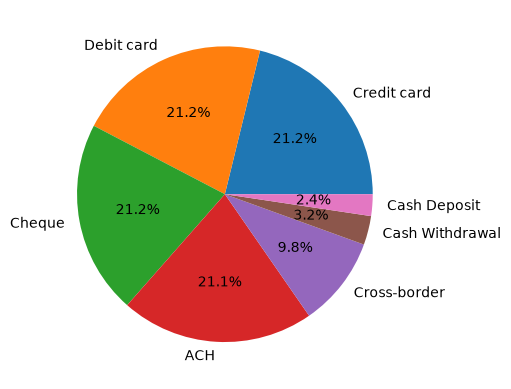

In [13]:
df['Payment_type'].value_counts().plot(kind='pie',autopct='%.1f%%')

In [14]:
df['Is_laundering'].value_counts()

Is_laundering
0    9494979
1       9873
Name: count, dtype: int64

In [15]:
df['Laundering_type'].value_counts().nlargest(5)

Laundering_type
Normal_Small_Fan_Out      3477717
Normal_Fan_Out            2302220
Normal_Fan_In             2104285
Normal_Group               528351
Normal_Cash_Withdrawal     305031
Name: count, dtype: int64

#### Bivariate Analysis

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

In [17]:
pd.crosstab(df['Payment_type'],df['Is_laundering'])

Is_laundering,0,1
Payment_type,,
ACH,2007648,1159
Cash Deposit,223801,1405
Cash Withdrawal,299143,1334
Cheque,2010332,1087
Credit card,2011773,1136
Cross-border,931303,2628
Debit card,2010979,1124


In [18]:
df['Sender_account']=df['Sender_account'].astype('str')

In [19]:
df['Receiver_account']=df['Receiver_account'].astype('str')

In [20]:
df.drop(columns=['Sender_account','Laundering_type','Receiver_account','Date','Time'],inplace=True)

In [21]:
df.columns

Index(['Amount', 'Payment_currency', 'Received_currency',
       'Sender_bank_location', 'Receiver_bank_location', 'Payment_type',
       'Is_laundering'],
      dtype='str')

In [22]:
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (classification_report, average_precision_score,
                             roc_auc_score, precision_recall_curve)
from imblearn.over_sampling import SMOTE

# Keep ALL fraud rows, sample the normal ones
pos = df[df['Is_laundering'] == 1]
neg = df[df['Is_laundering'] == 0].sample(n=200000, random_state=23)
df_s = pd.concat([pos, neg]).sample(frac=1, random_state=23)

x = df_s.drop(columns=['Is_laundering'])
y = df_s['Is_laundering']
cat_columns = x.select_dtypes(include=['str', 'object']).columns
num_cols = x.select_dtypes(exclude=['str', 'object']).columns

# Split FIRST
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, stratify=y, random_state=23)
x_train, x_val, y_train, y_val = train_test_split(
    x_train, y_train, test_size=0.2, stratify=y_train, random_state=23)

preprocess = ColumnTransformer([
    ('cat', OneHotEncoder(dtype='int', handle_unknown='ignore', sparse_output=False), cat_columns),
    ('num', StandardScaler(), num_cols),
])
X_tr = preprocess.fit_transform(x_train)
X_va = preprocess.transform(x_val)
X_te = preprocess.transform(x_test)

# SMOTE on train only
X_tr_s, y_tr_s = SMOTE(random_state=23).fit_resample(X_tr, y_train)
print(X_tr_s.shape, X_va.shape, X_te.shape)

(256000, 70) (33580, 70) (41975, 70)


In [23]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.optimizers import SGD, RMSprop, Adam
from tensorflow.keras.callbacks import EarlyStopping
import optuna

def objective(trial):
    n_layers = trial.suggest_int('n_layers', 1, 4)
    learning_rate = trial.suggest_float('learning_rate', 1e-4, 1e-2, log=True)
    batch_size = trial.suggest_categorical('batch_size', [64, 128, 256, 512])
    optimizer_name = trial.suggest_categorical('optimizer', ['adam', 'rmsprop', 'sgd'])
    units = trial.suggest_int('units_layer', 8, 64)
    dropout_rate = trial.suggest_float('dropout_layer', 0.0, 0.5)
    activation = trial.suggest_categorical('activatation', ['relu', 'tanh'])

    model = Sequential([Input(shape=(X_tr_s.shape[1],))])
    for _ in range(n_layers):
        model.add(Dense(units, activation=activation))
        model.add(Dropout(dropout_rate))
    model.add(Dense(1, activation='sigmoid'))

    opt = {'adam': Adam, 'rmsprop': RMSprop, 'sgd': SGD}[optimizer_name](learning_rate=learning_rate)
    model.compile(optimizer=opt, loss='binary_crossentropy',
                  metrics=[tf.keras.metrics.AUC(curve='PR', name='pr_auc')])

    early_stop = EarlyStopping(monitor='val_pr_auc', mode='max', patience=5,
                               restore_best_weights=True)
    history = model.fit(X_tr_s, y_tr_s, validation_data=(X_va, y_val),
                        epochs=50, batch_size=batch_size,
                        callbacks=[early_stop], verbose=0)
    return max(history.history['val_pr_auc'])

study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=23))
study.optimize(objective, n_trials=30)
best = study.best_params
print(best, study.best_value)

[I 2026-11-18 19:42:59,828] A new study created in memory with name: no-name-6de0d40b-8492-40f7-aa53-90d717c7dafc


[I 2026-11-18 19:45:34,486] Trial 0 finished with value: 0.26121798157691956 and parameters: {'n_layers': 3, 'learning_rate': 0.007832947354227425, 'batch_size': 64, 'optimizer': 'sgd', 'units_layer': 31, 'dropout_layer': 0.0012324406004430855, 'activatation': 'tanh'}. Best is trial 0 with value: 0.26121798157691956.
[I 2026-11-18 19:47:24,311] Trial 1 finished with value: 0.26625001430511475 and parameters: {'n_layers': 2, 'learning_rate': 0.0015106495666125258, 'batch_size': 64, 'optimizer': 'rmsprop', 'units_layer': 14, 'dropout_layer': 0.00026440558463802777, 'activatation': 'relu'}. Best is trial 1 with value: 0.26625001430511475.
[I 2026-11-18 19:50:47,949] Trial 2 finished with value: 0.24933411180973053 and parameters: {'n_layers': 2, 'learning_rate': 0.0004931498215388464, 'batch_size': 64, 'optimizer': 'rmsprop', 'units_layer': 12, 'dropout_layer': 0.415602627845209, 'activatation': 'relu'}. Best is trial 1 with value: 0.26625001430511475.
[I 2026-11-18 19:53:28,939] Trial 3 

{'n_layers': 2, 'learning_rate': 0.0008683219157613116, 'batch_size': 64, 'optimizer': 'adam', 'units_layer': 17, 'dropout_layer': 0.11377963144663038, 'activatation': 'tanh'} 0.2862911522388458


In [24]:
model = Sequential([Input(shape=(X_tr_s.shape[1],))])
for _ in range(best['n_layers']):
    model.add(Dense(best['units_layer'], activation=best['activatation']))
    model.add(Dropout(best['dropout_layer']))
model.add(Dense(1, activation='sigmoid'))

opt = {'adam': Adam, 'rmsprop': RMSprop, 'sgd': SGD}[best['optimizer']](learning_rate=best['learning_rate'])
model.compile(optimizer=opt, loss='binary_crossentropy',
              metrics=[tf.keras.metrics.AUC(curve='PR', name='pr_auc'),
                       tf.keras.metrics.Precision(name='precision'),
                       tf.keras.metrics.Recall(name='recall')])

history = model.fit(
    X_tr_s, y_tr_s, validation_data=(X_va, y_val),
    epochs=100, batch_size=best['batch_size'],
    callbacks=[EarlyStopping(monitor='val_pr_auc', mode='max', patience=7,
                             restore_best_weights=True)])

# Threshold from validation, final check on test
val_prob = model.predict(X_va).ravel()
prec, rec, thr = precision_recall_curve(y_val, val_prob)
f1 = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-9)
threshold = thr[np.argmax(f1)]

test_prob = model.predict(X_te).ravel()
test_pred = (test_prob >= threshold).astype(int)
print('Threshold:', threshold)
print('PR-AUC :', average_precision_score(y_test, test_prob))
print('ROC-AUC:', roc_auc_score(y_test, test_prob))
print(classification_report(y_test, test_pred, digits=3))

Epoch 1/100
4000/4000 ━━━━━━━━━━━━━━━━━━━━ 11s 2ms/step - loss: 0.5728 - pr_auc: 0.7703 - precision: 0.7805 - recall: 0.6228 - val_loss: 0.5491 - val_pr_auc: 0.2477 - val_precision: 0.1494 - val_recall: 0.6329
Epoch 2/100
4000/4000 ━━━━━━━━━━━━━━━━━━━━ 8s 2ms/step - loss: 0.5653 - pr_auc: 0.7775 - precision: 0.7813 - recall: 0.6406 - val_loss: 0.5486 - val_pr_auc: 0.2537 - val_precision: 0.1485 - val_recall: 0.6342
Epoch 3/100
4000/4000 ━━━━━━━━━━━━━━━━━━━━ 8s 2ms/step - loss: 0.5644 - pr_auc: 0.7797 - precision: 0.7802 - recall: 0.6439 - val_loss: 0.5699 - val_pr_auc: 0.2533 - val_precision: 0.1476 - val_recall: 0.6437
Epoch 4/100
4000/4000 ━━━━━━━━━━━━━━━━━━━━ 8s 2ms/step - loss: 0.5635 - pr_auc: 0.7809 - precision: 0.7790 - recall: 0.6455 - val_loss: 0.5170 - val_pr_auc: 0.2576 - val_precision: 0.1492 - val_recall: 0.6348
Epoch 5/100
4000/4000 ━━━━━━━━━━━━━━━━━━━━ 8s 2ms/step - loss: 0.5630 - pr_auc: 0.7821 - precision: 0.7789 - recall: 0.6469 - val_loss: 0.5755 - val_pr_auc: 0.2560

In [25]:
import joblib
joblib.dump(preprocess, 'preprocess.pkl')
model.save('aml_model.keras')

def predict_transaction(txn: dict):
    row = pd.DataFrame([txn])
    p = model.predict(preprocess.transform(row), verbose=0)[0][0]
    return {'suspicion_score': float(p), 'flag': bool(p >= threshold)}

In [26]:
import json
with open('threshold.json', 'w') as f:
    json.dump({'threshold': float(threshold)}, f)